# 16-FreeRTOS事件组与多事件同步


## 1. 本篇内容与学习目标

本篇主要依据 `21事件组.pptx`，学习用 FreeRTOS 事件组表示多个事件状态，实现“任意条件满足”“所有条件满足”和多个任务的同步汇合。

主课件共14页，第1—13页为封面、目录、目标和教学内容，第14页为品牌结束页。本篇覆盖事件组定义、标志位布局、创建/等待/设置 API、按键通知案例、两种等待模式、`xEventGroupSync()` 以及开发注意事项。

课件中部分 API 写法与标准 FreeRTOS 接口不一致，本篇结合官方 `event_groups.h` 校正，具体差异写在相应章节。代码属于说明性示例，需要工程配置和板级驱动配合，未进行开发板编译、下载或运行验证。


## 2. 什么是事件组

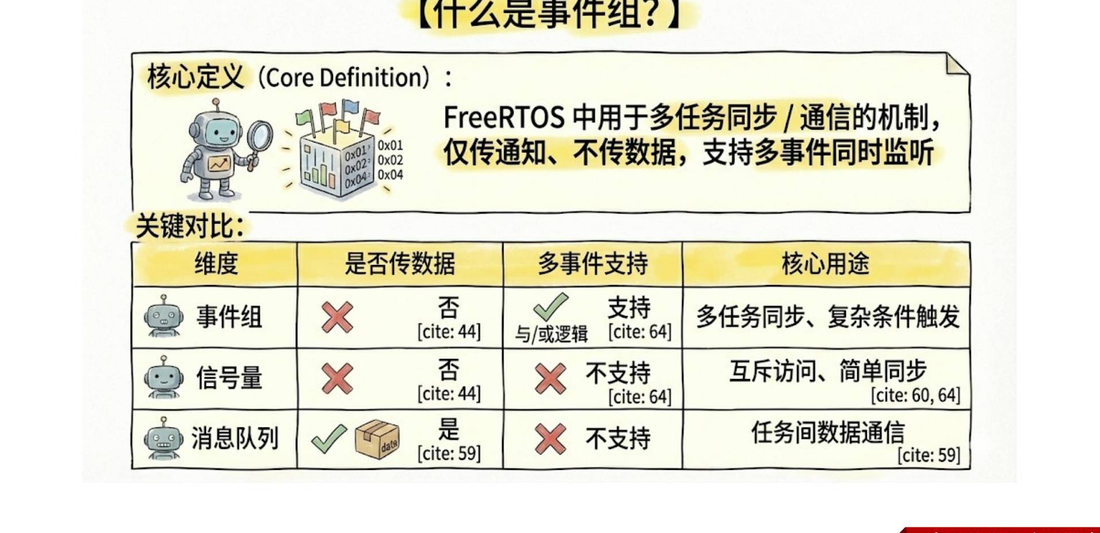

事件组（Event Group）是一组事件标志位。每一位表示一个应用约定的状态：0表示未置位，1表示已置位。任务可以等待某一个位，也可以同时等待一组位。

例如机器人启动前需要等待“电机初始化完成”和“传感器初始化完成”。两个初始化任务分别设置自己的位，控制任务等待这两个位同时为1，随后开始控制。

| 机制 | 表达的内容 | 常见用途 |
|---|---|---|
| 事件组 | 多个事件状态位，支持与/或等待 | 多条件就绪、任务广播通知、同步汇合 |
| 二值信号量 | 一个事件是否发生或一个同步许可 | 简单唤醒、任务与中断同步 |
| 计数信号量 | 可用资源或待处理事件的数量 | 资源池、次数累计 |
| 互斥信号量 | 共享资源的所有权 | 外设、数据结构的互斥访问 |
| 消息队列 | 有顺序的数据元素 | 采样值、命令、结构体传输 |

事件组只保存位状态，不携带采样值、字符串等消息正文。同一个位已经是1时再次置1，不会累计次数，也不保存发生顺序。必须保留每次事件时，应选择计数信号量或消息队列。

课件对“多事件支持”的比较，是指事件组直接支持组合位条件；其他机制仍可以通过多个对象或额外程序逻辑实现复杂通信。保护共享资源优先采用互斥信号量。


## 3. 标志位布局与掩码

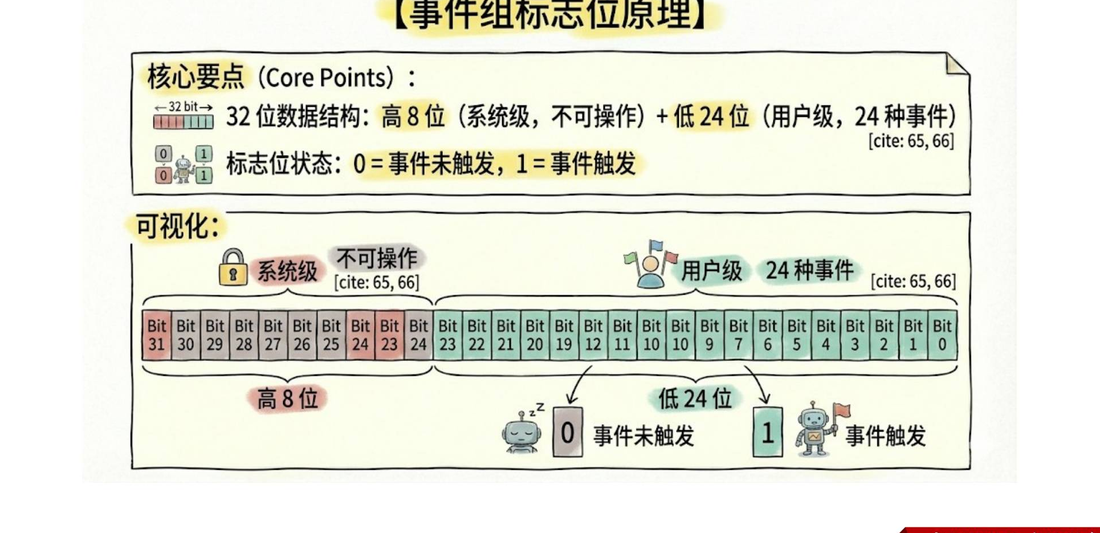

课件按32位 `EventBits_t` 讲解：高8位供内核使用，低24位供应用使用，即应用位0—23。用户不能设置内核保留位。

这个数量依赖内核配置，并非所有平台都固定为24位。常见16位配置提供8个应用位，32位配置提供24个；支持64位 tick 的较新内核可提供56个。旧版本常通过 `configUSE_16_BIT_TICKS` 配置，新版本可采用 `configTICK_TYPE_WIDTH_IN_BITS`。应以项目中的 `event_groups.h`、`FreeRTOSConfig.h` 和内核版本为准。

定义独立位和组合掩码：

```c
#define EVT_MOTOR_READY   ((EventBits_t)1U << 0)
#define EVT_SENSOR_READY  ((EventBits_t)1U << 1)
#define EVT_ALL_READY     (EVT_MOTOR_READY | EVT_SENSOR_READY)
```

这里 `|` 用于构造“我要关注哪些位”的掩码。等待是与逻辑还是或逻辑，由 `xWaitForAllBits` 参数决定。不要把 `EVT_ALL_READY` 定义成两个掩码按位与，那样两个独立位的交集会变成0。

事件位名称应表达明确业务语义，例如“初始化完成”或“按键事件”。同一位不要同时表示两种状态，否则接收方无法判断发生了什么。


## 4. 创建事件组

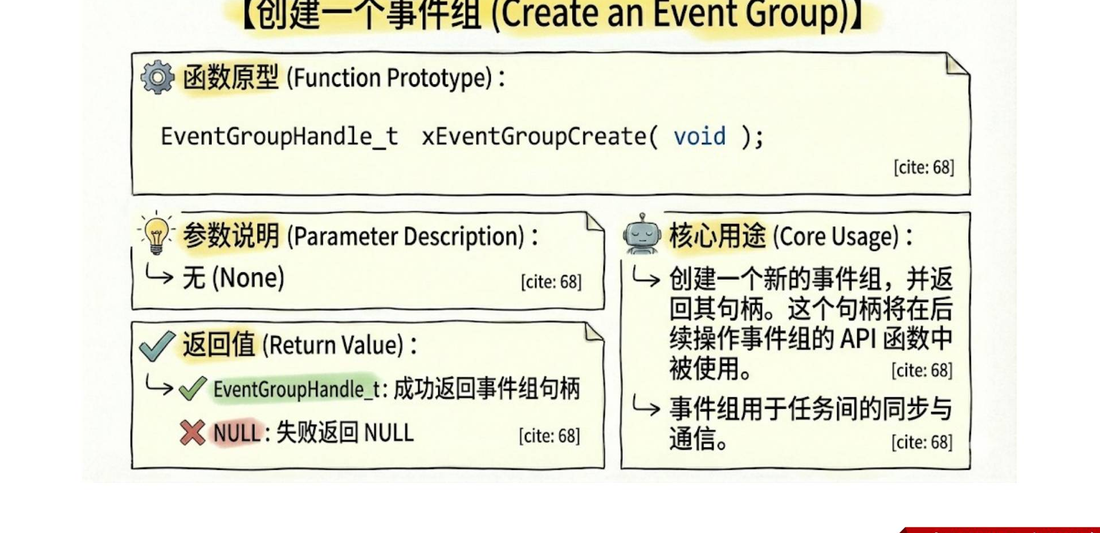

动态创建 API：

```c
EventGroupHandle_t xEventGroupCreate(void);
```

创建成功返回事件组句柄，失败返回 `NULL`。新事件组的所有事件位初始为0。句柄必须在通知和等待任务启动前创建并检查：

```c
#include "FreeRTOS.h"
#include "task.h"
#include "event_groups.h"

static EventGroupHandle_t readyGroup;

BaseType_t create_ready_group(void)
{
    readyGroup = xEventGroupCreate();
    return readyGroup != NULL ? pdPASS : pdFAIL;
}
```

若返回 `pdFAIL`，应用应停止启动依赖它的任务并报告错误。动态创建需要工程支持动态内存分配；也可使用 `xEventGroupCreateStatic()`，由应用提供 `StaticEventGroup_t` 控制块。

工程需编入 `event_groups.c`，并启用所用版本要求的事件组配置。当前内核存在 `configUSE_EVENT_GROUPS`，旧版本配置可能不同，不能照搬一个版本的配置表。


## 5. 等待事件：xEventGroupWaitBits

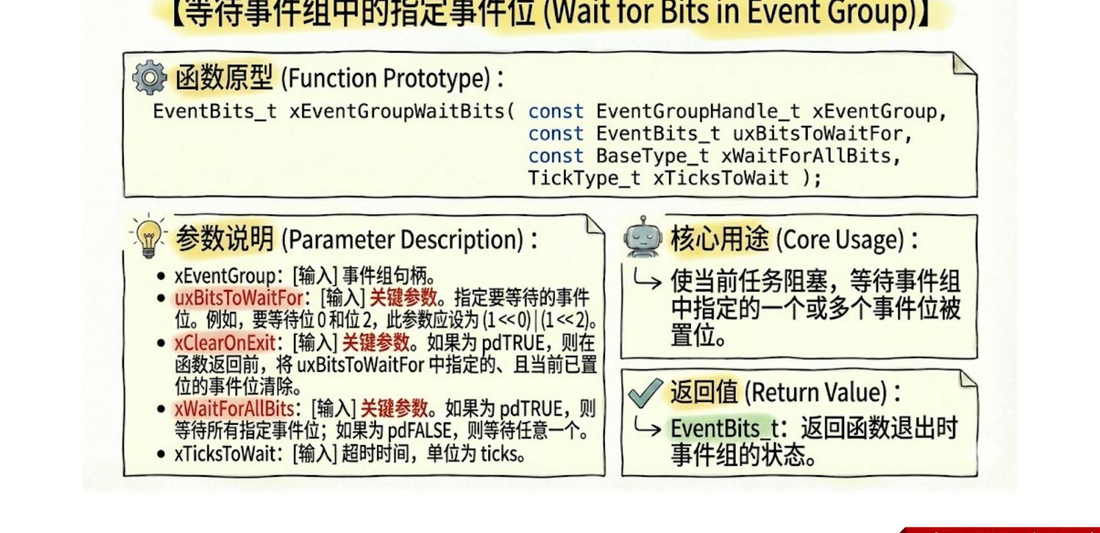

**课件第7页的函数原型漏掉了 `xClearOnExit` 参数。** 标准接口有5个参数，正确原型为：

```c
EventBits_t xEventGroupWaitBits(
    EventGroupHandle_t xEventGroup,
    EventBits_t uxBitsToWaitFor,
    BaseType_t xClearOnExit,
    BaseType_t xWaitForAllBits,
    TickType_t xTicksToWait
);
```

| 参数 | 作用 |
|---|---|
| `xEventGroup` | 已创建的事件组句柄 |
| `uxBitsToWaitFor` | 要等待的非零应用位掩码 |
| `xClearOnExit` | 条件满足时，是否在返回前清除等待掩码指定的位 |
| `xWaitForAllBits` | `pdTRUE` 等待所有位，`pdFALSE` 等待任意位 |
| `xTicksToWait` | 等待时长，单位为系统 tick |

若条件已经满足，函数立即返回；否则任务在允许的等待时间内进入阻塞态。返回值是事件位快照，而不是 `pdPASS`/`pdFAIL`。条件满足且自动清位时，返回的是清位前的快照，因此仍能用它判断触发原因。

等待两个初始化条件，最多1000 ms：

```c
EventBits_t bits = xEventGroupWaitBits(
    readyGroup, EVT_ALL_READY,
    pdFALSE, pdTRUE, pdMS_TO_TICKS(1000)
);

if ((bits & EVT_ALL_READY) == EVT_ALL_READY) {
    start_control();
} else {
    report_initialization_timeout(bits);
}
```

超时可能返回部分已置位的事件，不应仅以“返回值不为0”判断所有条件满足。上述示例保留就绪状态，适合一次初始化；反复循环等待这些保留位会持续立即返回，周期性事件应重新设计清位规则。

`0` 表示不等待，`pdMS_TO_TICKS()` 将毫秒转换为 tick；`portMAX_DELAY` 在 `INCLUDE_vTaskSuspend` 为1时可表示无限等待，否则是很长的有限等待。等待 API 只能在任务上下文使用。


## 6. 设置事件：xEventGroupSetBits

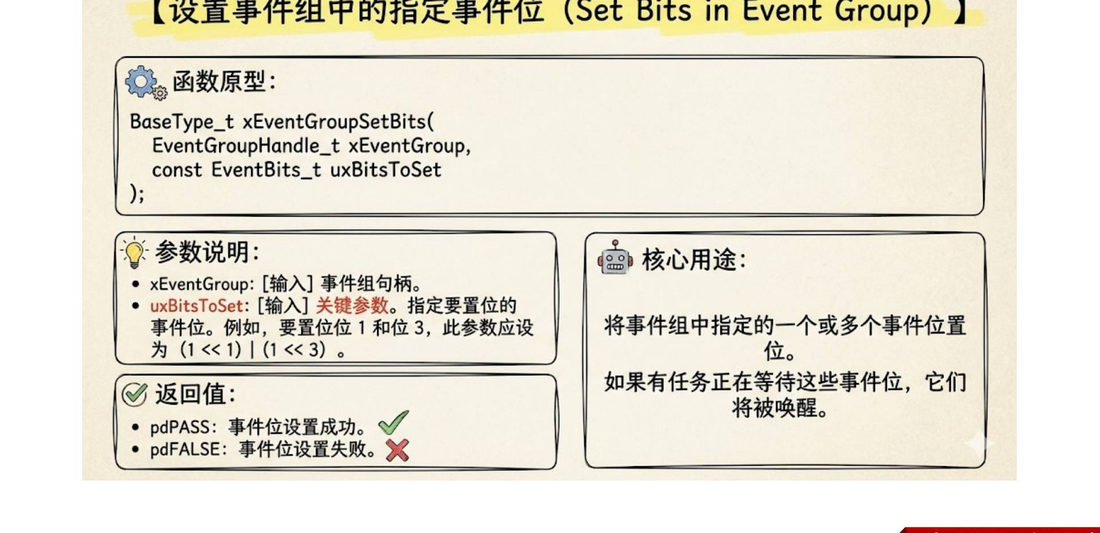

**课件第8页把返回类型写成 `BaseType_t`，并描述成 `pdPASS`/`pdFALSE`，这里需要纠正。** 任务 API 的正确原型为：

```c
EventBits_t xEventGroupSetBits(
    EventGroupHandle_t xEventGroup,
    EventBits_t uxBitsToSet
);
```

设置指定的一个或多个位，相当于把掩码按位或到当前事件状态上。其他位保持不变，符合等待条件的任务转为就绪态：

```c
// 电机初始化任务成功完成后
xEventGroupSetBits(readyGroup, EVT_MOTOR_READY);

// 传感器初始化任务成功完成后
xEventGroupSetBits(readyGroup, EVT_SENSOR_READY);
```

返回值是该调用返回时的事件组位值。被唤醒的任务可能自动清位或抢先执行并改变状态，因此返回值不保证包含本次刚设置的所有位。不要拿它与 `pdPASS` 比较来判断设置成功。

工程补充：`xEventGroupClearBits(group, mask)` 可主动清位，返回清位前的位值；`xEventGroupGetBits(group)` 可读取当前状态，但读取结果只是当时快照，不能代替等待 API 或互斥保护。


## 7. 两种等待模式：所有位与任意位

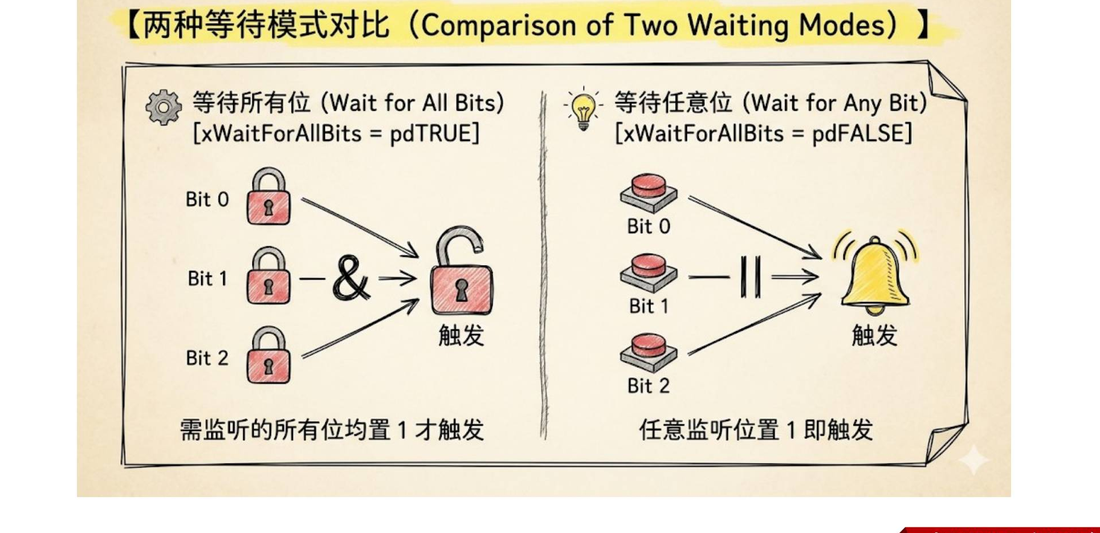

设等待掩码为位0和位1，即 `0b11`：

| 当前位状态 | 等待所有位 `pdTRUE` | 等待任意位 `pdFALSE` |
|---|---|---|
| `0b00` | 不满足 | 不满足 |
| `0b01` | 不满足 | 满足 |
| `0b10` | 不满足 | 满足 |
| `0b11` | 满足 | 满足 |

返回后的判断方式分别为：

```c
// 等待所有位：掩码中的每一位都已置位
if ((bits & mask) == mask) {
    handle_all_ready();
}

// 等待任意位：掩码中至少有一位置位
if ((bits & mask) != 0) {
    handle_any_event(bits & mask);
}
```

等待所有位适合“网络连接且时间同步完成”等组合就绪条件。等待任意位适合“按键1或按键2发生”后再区分具体事件。

自动清位是另一个独立选项。`xClearOnExit=pdTRUE` 在条件满足时清除整个等待掩码指定的位，而不只清除某一个触发位；单纯超时且条件未满足时，不会自动清除部分已置位的等待位。


## 8. 实战一：按键触发多任务通知

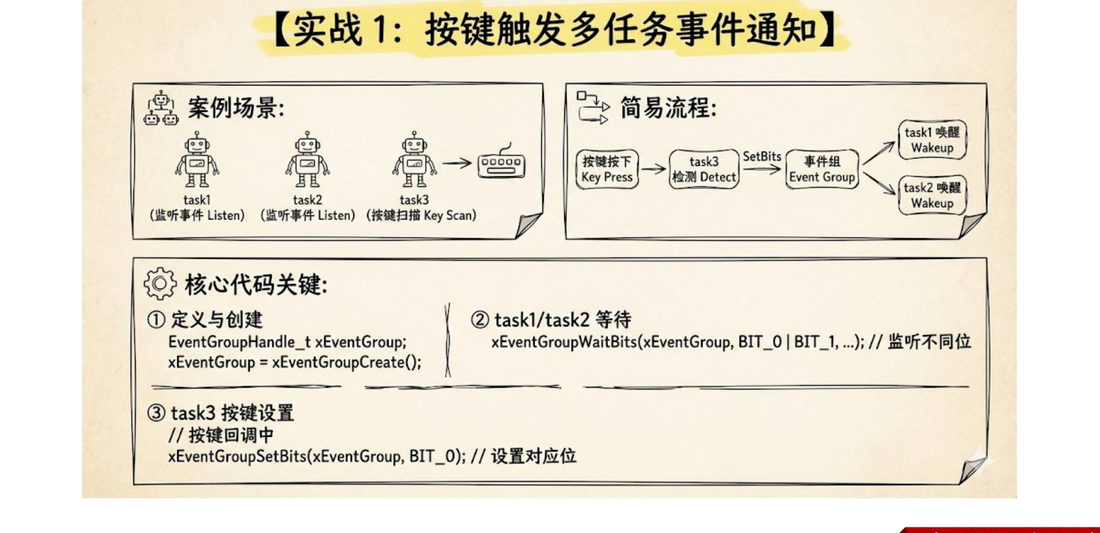

课件设计 task3 扫描按键并设置事件，task1、task2 监听各自的位。下面用位0、位1分别表示两个按键，监听任务处理后自动清位：

```c
#define EVT_KEY1 ((EventBits_t)1U << 0)
#define EVT_KEY2 ((EventBits_t)1U << 1)

static EventGroupHandle_t keyGroup;

void listener1(void *argument)
{
    for (;;) {
        EventBits_t bits = xEventGroupWaitBits(
            keyGroup, EVT_KEY1, pdTRUE, pdFALSE, portMAX_DELAY);
        if ((bits & EVT_KEY1) != 0) {
            handle_key1();
        }
    }
}

void listener2(void *argument)
{
    for (;;) {
        EventBits_t bits = xEventGroupWaitBits(
            keyGroup, EVT_KEY2, pdTRUE, pdFALSE, portMAX_DELAY);
        if ((bits & EVT_KEY2) != 0) {
            handle_key2();
        }
    }
}

void key_scan_task(void *argument)
{
    for (;;) {
        if (key1_pressed_once()) {
            xEventGroupSetBits(keyGroup, EVT_KEY1);
        }
        if (key2_pressed_once()) {
            xEventGroupSetBits(keyGroup, EVT_KEY2);
        }
        vTaskDelay(pdMS_TO_TICKS(10));
    }
}
```

启动前创建 `keyGroup` 并检查非 `NULL`。按键函数约定输出经过消抖的单次按下事件，处理函数由具体项目实现。这里按键检测和设置事件都在任务上下文执行；中断回调需要换成 ISR 专用设置 API。

广播补充：多个已经阻塞在同一位上的任务，可以在一次置位时都满足条件并被唤醒。某个等待者启用自动清位，不会阻止内核在这次置位处理中检查其他已阻塞的等待者。但之后才开始等待的任务可能看不到已经清除的事件，因此不能据此保证所有未来订阅者都能收到通知。

快速连续按下会合并同一位的通知。若必须保留每一次按下及顺序，应使用第15篇的消息队列。


## 9. 实战二：xEventGroupSync 多任务汇合

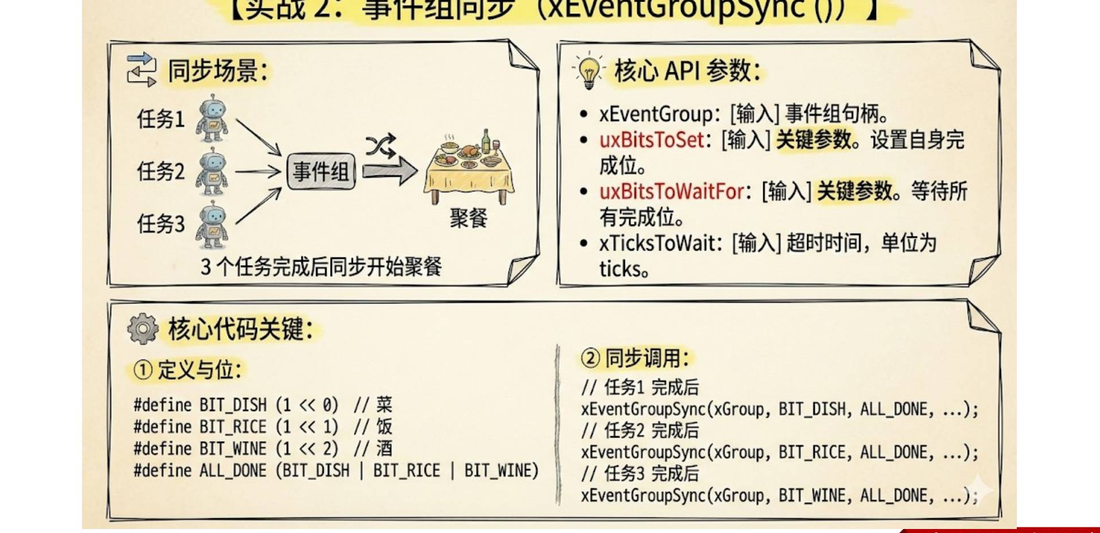

课件用“菜、饭、酒准备好后一起聚餐”说明同步屏障：每个任务先完成自己的工作，然后设置自己的完成位，并等待所有任务都到达同步点。

```c
EventBits_t xEventGroupSync(
    EventGroupHandle_t xEventGroup,
    EventBits_t uxBitsToSet,
    EventBits_t uxBitsToWaitFor,
    TickType_t xTicksToWait
);
```

它将“设置自己的位”和“等待全部完成位”作为一个同步操作处理。条件满足时，等待掩码中的位会自动清除，返回值提供清除前的位快照。

```c
#define BIT_DISH ((EventBits_t)1U << 0)
#define BIT_RICE ((EventBits_t)1U << 1)
#define BIT_WINE ((EventBits_t)1U << 2)
#define ALL_DONE (BIT_DISH | BIT_RICE | BIT_WINE)

// 三个任务共享已成功创建的 diningGroup
// 菜任务调用 BIT_DISH，饭任务调用 BIT_RICE，酒任务调用 BIT_WINE
BaseType_t join_dinner(EventBits_t my_bit)
{
    EventBits_t bits = xEventGroupSync(
        diningGroup, my_bit, ALL_DONE, pdMS_TO_TICKS(5000));
    if ((bits & ALL_DONE) == ALL_DONE) {
        return pdPASS;
    }
    report_barrier_timeout(bits);
    return pdFAIL;
}
```

每个任务只在完成自己本轮准备后调用一次，成功后进入下一阶段。不要用普通 `SetBits` 后紧跟自动清位的 `WaitBits` 随意替代屏障，其他任务可能在中间改变状态，造成某个参与者错过这一轮同步。

同步超时只表示屏障条件未满足，不会取消其他任务，也不会自动撤销本任务已经设置的完成位。反复同步时，需要设计统一的超时恢复和轮次管理，避免上一轮残留位被下一轮误用。`xEventGroupSync()` 不能在 ISR 中使用。


## 10. 开发注意事项与课件纠正

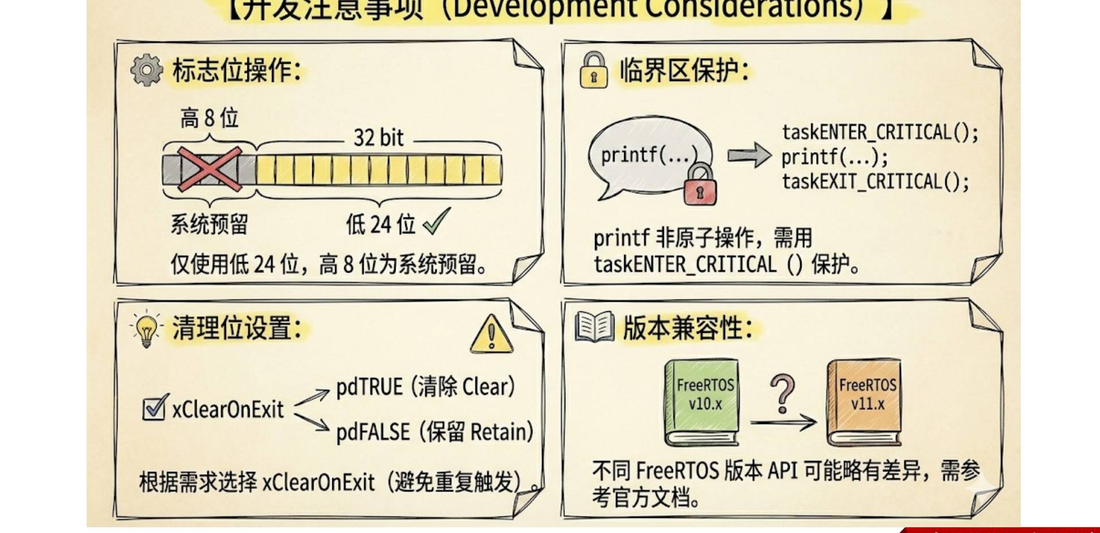

### 位范围与清位规则

只操作当前内核配置允许的应用位，等待掩码不要为0。一次性就绪状态可以保留；需要反复消费的事件常用自动清位。事件组没有“消息数量”，连续置位可能合并。

### 打印和共享外设保护

课件建议用临界区包围 `printf()`。实际工程要先检查输出函数是否阻塞、是否依赖中断或 DMA，以及持锁时间。长时间关中断打印会影响实时性，等待被屏蔽的中断还可能卡住。

多个任务共享串口输出时，通常更适合用 Mutex 保护任务中的短发送操作，或者由统一日志任务通过队列发送。事件位不能提供共享资源所有权和优先级继承，也不会使普通全局变量访问自动变得安全。

### ISR 设置是延后处理

`xEventGroupSetBitsFromISR()` 与任务版不同：它把设置请求交给定时器服务任务处理，返回 `pdPASS` 表示请求成功入队，而非事件位已立即设置。服务队列满时可返回 `pdFAIL`。工程还需满足对应版本的 `configUSE_TIMERS`、`INCLUDE_xTimerPendFunctionCall` 等配置要求。

```c
// 中断片段：遵守当前端口允许调用内核 API 的中断优先级
BaseType_t higher_priority_woken = pdFALSE;
BaseType_t result = xEventGroupSetBitsFromISR(
    keyGroup, EVT_KEY1, &higher_priority_woken);
if (result != pdPASS) {
    record_event_request_failure_from_isr();
}
portYIELD_FROM_ISR(higher_priority_woken);
```

ISR 内的失败记录函数必须简短且不阻塞。`portYIELD_FROM_ISR` 写法由具体移植端口决定。不能在 ISR 中调用 `WaitBits` 或 `Sync` 来等待其他任务。

### 句柄生命周期与版本

创建失败后不要继续调用事件组 API。删除事件组前，应停止生产者、处理等待者和可能尚未执行的 ISR 延后请求，避免访问失效句柄。函数原型、配置和位宽以项目实际头文件为准。

本篇接口纠正依据：[FreeRTOS 官方事件组头文件](https://github.com/FreeRTOS/FreeRTOS-Kernel/blob/main/include/event_groups.h)。该参考补充接口语义，教学案例仍以课程 PPT 为主。截图中的 `[cite: ...]` 是课件原有标记，未作为本篇参考文献编号。


## 11. 设计检查与调试方法

先列出每个位的“谁设置、谁等待、何时清除、是否需要计数”，再确定使用与逻辑还是或逻辑。检查消息正文是否需要单独放入队列，以及相关共享数据是否有明确的互斥和生命周期规则。

建议验证以下场景：

1. 初始位为0，有限超时等待返回时，目标掩码不满足。
2. 只设置位0：等待任意位的任务满足，等待位0和位1全部完成的任务继续等待。
3. 再设置位1：全部等待条件满足，检查返回快照和自动清位后的状态。
4. 重复设置已经为1的位，确认状态没有累计为多次事件。
5. 三个任务分别调用 `Sync`，确认最后一位到达前均不进入下一阶段；故意缺少一个任务，验证超时恢复。
6. 中断通知时区分“请求入队时间”和“服务任务实际置位时间”，记录服务队列满的失败次数。

读取位状态可辅助调试，但不要把一个瞬时快照当作所有任务的完整执行记录。日志建议包含任务名、等待掩码、与/或模式、清位设置、返回位值和时间戳。

这些是待执行的验证方案，本篇没有声称已完成板级测试。


## 12. 核心总结

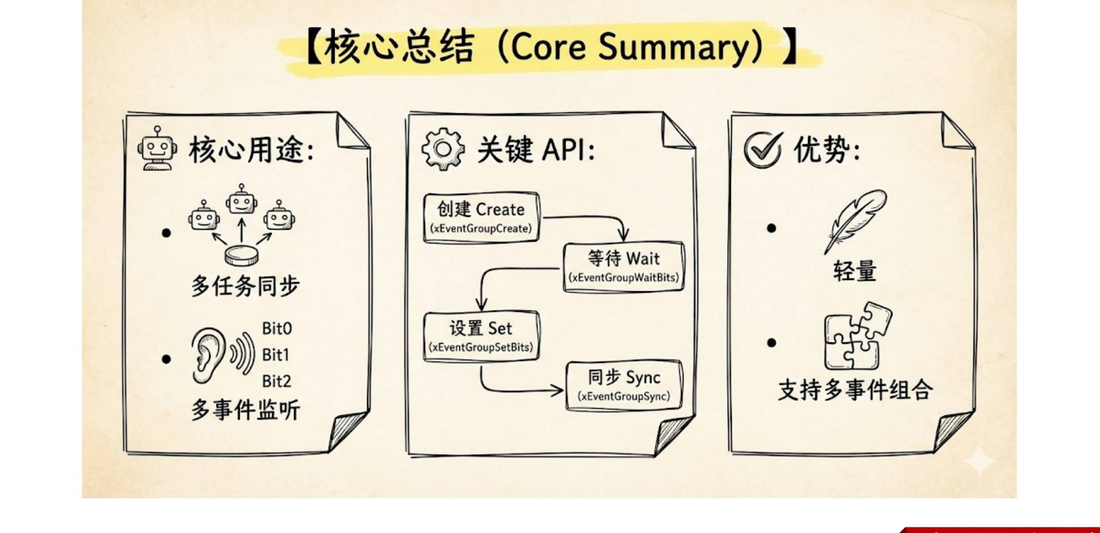

- **表示状态**：事件组把多个事件映射为独立位，提供多事件通知和组合条件等待，不保存业务数据、事件次数或发生顺序。
- **创建**：`xEventGroupCreate()` 返回句柄，必须检查 `NULL`，新事件组初始为0。
- **等待**：`xEventGroupWaitBits()` 有5个参数，通过 `xWaitForAllBits` 选择所有位或任意位，通过 `xClearOnExit` 决定条件满足后的清位行为。
- **设置**：任务版 `xEventGroupSetBits()` 返回 `EventBits_t` 位值；ISR 版的返回值表达延后请求是否成功入队。
- **同步**：`xEventGroupSync()` 适合多个任务的同步汇合，超时和重复轮次需要应用自行协调。
- **选型**：多条件就绪用事件组，数据和顺序用队列，次数用计数信号量，共享资源所有权用 Mutex。

本篇依据课程 PPT 整理，并校正部分 API 描述；未进行开发板编译、下载或运行验证。
